# 04 — Gross Rental Yield, Risk Score & Budget Recommender

Computes trailing-12-month **gross rental yield** (`annual rent / purchase price`, winsorized, preferring `New` Ejari contracts over renewals) paired with a composite **Risk Score** combining trailing price volatility, transaction liquidity, and sample confidence.

> **Important**: Gross yield excludes ~4% DLD transfer fees, agency fees, annual Oqood/DEWA/service charges, and vacancy.

In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dfv.config import PATHS, get_data_mode

mode = get_data_mode()
data_dir = PATHS.processed if mode == "processed" else PATHS.sample
print(f"Active data mode: {mode} | Directory: {data_dir}")

from dfv.analysis.yield_score import compute_yield_and_risk, recommend_areas_for_budget

Active data mode: sample | Directory: /Users/shahinhamza/.gemini/antigravity/scratch/dubai-fair-value/data/sample


In [2]:
yr_json = data_dir / "analysis" / "yield_risk.json"
if yr_json.exists():
    yr = json.loads(yr_json.read_text(encoding="utf-8"))
else:
    tx = pd.read_parquet(data_dir / "transactions.parquet")
    rents = pd.read_parquet(data_dir / "rent_contracts.parquet")
    yr = compute_yield_and_risk(tx, rents, min_sales=8, min_rents=6)

print("Caveat:", yr["caveat"])
area_df = pd.DataFrame(yr["area_ranking"])
area_df.head(10)

Caveat: Gross rental yield equals annual rent divided by purchase price using trailing 12-month medians. It ignores DLD transfer fees (4%), Oqood/agency fees, service charges, vacancy, and maintenance costs.


,area_name,gross_yield_pct,risk_score,yield_per_risk_score,median_price_aed,median_sale_ppsqm,median_rent_ppsqm,sales_12m_count,rents_12m_count,confidence
0,Jumeirah Village Circle,6.94,47.6,2.684,2023841.0,15000.0,1040.0,68,41,High
1,Discovery Gardens,7.05,67.6,2.168,1361325.0,14582.8,1029.2,7,6,Low
2,Business Bay,5.98,54.2,2.129,2496009.0,25503.3,1521.7,71,62,High
3,Jumeirah Lake Towers,6.82,66.4,2.122,2567894.0,20289.9,1383.1,30,57,Medium
4,Dubai South,6.57,70.4,1.964,1797477.0,10940.3,717.2,28,27,Medium
5,Dubai Creek Harbour,5.47,53.9,1.956,2341775.0,25672.0,1404.5,37,22,Medium
6,Damac Hills,5.74,60.7,1.900,3841903.0,16764.7,960.6,29,36,Medium
7,Dubai Marina,5.52,63.8,1.766,2424695.0,28937.7,1598.6,47,29,High
8,Downtown Dubai,4.43,47.0,1.725,3573429.0,37133.6,1642.9,57,27,High
9,Dubai Hills Estate,5.07,59.9,1.692,4507754.0,23587.5,1192.6,45,24,High


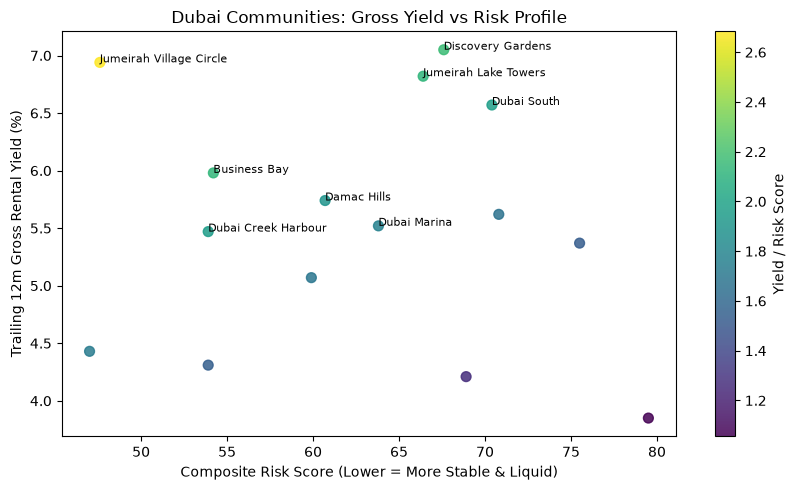

Sample Query — Top 1-Bed Units Under AED 1.5M:


,area_name,property_type,rooms,median_price_aed,median_sale_ppsqm,median_rent_ppsqm,gross_yield_pct,monthly_price_vol,sales_12m_count,rents_12m_count,new_contract_share_pct,used_new_contracts_only,match_level,confidence,risk_score,yield_per_risk_score
0,Jumeirah Village Circle,Unit,1,1051246.0,15078.0,1090.5,7.23,0.0665,17,13,68.4,True,segment,Medium,47.6,2.798
1,Discovery Gardens,Unit,1,852066.0,13770.9,967.0,7.02,0.1008,3,3,66.7,False,segment,Low,67.6,2.158
2,Damac Hills,Unit,1,1204141.0,16079.3,1002.4,6.23,0.0920,5,3,75.0,True,segment,Low,60.0,2.078
3,Dubai South,Unit,1,771663.0,11041.7,748.1,6.78,0.1315,7,10,20.0,False,segment,Low,70.4,2.025
4,Jumeirah Lake Towers,Unit,1,1435498.0,20339.9,1298.5,6.38,0.1053,8,4,33.3,True,segment,Low,65.2,2.011


In [3]:
if not area_df.empty:
    fig, ax = plt.subplots(figsize=(8.5, 5))
    sc = ax.scatter(
        area_df["risk_score"],
        area_df["gross_yield_pct"],
        s=np.clip(area_df["sales_12m_count"] * 0.6, 50, 450),
        c=area_df["yield_per_risk_score"],
        cmap="viridis",
        alpha=0.85,
    )
    for _, r in area_df.head(8).iterrows():
        ax.annotate(r["area_name"], (r["risk_score"], r["gross_yield_pct"]), fontsize=8)
    ax.set_xlabel("Composite Risk Score (Lower = More Stable & Liquid)")
    ax.set_ylabel("Trailing 12m Gross Rental Yield (%)")
    ax.set_title("Dubai Communities: Gross Yield vs Risk Profile")
    fig.colorbar(sc, label="Yield / Risk Score")
    plt.tight_layout()
    plt.show()

print("Sample Query — Top 1-Bed Units Under AED 1.5M:")
pd.DataFrame(
    recommend_areas_for_budget(
        yr["segment_ranking"], budget_aed=1_500_000.0, rooms=1, property_type="Unit", top_k=5
    )
)